# Part 0 — PyTorch, just enough for Transformers

⏱ **~1.5 hours** · 📁 everything happens in this notebook

A Transformer is built from only a handful of tensor operations. This notebook teaches exactly those: you'll use every one of them again in attention.

**How to work through every notebook in this project**
- Run cells top to bottom with **Shift+Enter**.
- Cells marked **✍️ Your turn** contain `raise NotImplementedError` or `= None  # TODO`. Replace that with your code.
- The cell after an exercise checks your answer: ✅ means move on, ❌ comes with a hint.
- Stuck for more than ~10 minutes? Look at the same notebook in `solutions/notebooks/`, close it, then write the code yourself.

> **The one habit that matters most:** before you run a line, say out loud the **shape** you expect. Most Transformer bugs are shape bugs.

In [1]:
# Setup: run this cell first.
%load_ext autoreload
%autoreload 2
import sys, pathlib
root = pathlib.Path.cwd()
while not (root / "minitf").is_dir() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from minitf import check, viz
torch.manual_seed(0);
print("project folder:", root, "| torch", torch.__version__)

project folder: /Users/johngeorge/Desktop/Transformer/solutions | torch 2.8.0


## 1. Tensors

A **tensor** is an n-dimensional array, like a NumPy array, with two superpowers: it can live on a GPU, and it can track gradients.

In [2]:
x = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])
print(x)
print("shape:", x.shape, "| dtype:", x.dtype, "| device:", x.device)
print(torch.zeros(2, 3))
print(torch.randn(2, 3))      # random numbers from a normal distribution (mean 0, std 1)
print(torch.arange(6))

tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: torch.Size([2, 3]) | dtype: torch.float32 | device: cpu
tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[ 1.5410, -0.2934, -2.1788],
        [ 0.5684, -1.0845, -1.3986]])
tensor([0, 1, 2, 3, 4, 5])


In a Transformer almost every tensor has the shape **`(B, T, d)`**:
- **B**: batch size, how many sentences we process at once
- **T**: sequence length, tokens per sentence
- **d**: how many numbers describe each token

Indexing works like NumPy: `x[0]` is the first item, `x[:, -1]` means "all of dim 0, last item of dim 1".

### ✍️ Your turn
Make `batch`, a random tensor for **4 sentences × 7 tokens × 16 numbers**. Then take out:
- `first_sentence`: every token of sentence 0, shape `(7, 16)`
- `last_token_vectors`: the **last** token of **every** sentence, shape `(4, 16)`

In [3]:
batch = torch.randn(4, 7, 16)
first_sentence = batch[0]
last_token_vectors = batch[:, -1]

In [4]:
check.shape("batch", batch, (4, 7, 16))
check.shape("first_sentence", first_sentence, (7, 16))
check.shape("last_token_vectors", last_token_vectors, (4, 16))
check.close("last_token_vectors", last_token_vectors, batch[:, 6])

✅ batch: shape (4, 7, 16)
✅ first_sentence: shape (7, 16)
✅ last_token_vectors: shape (4, 16)
✅ last_token_vectors is correct


## 2. Matrix multiplication: the heart of everything

`A @ B` works when A's **last** dim equals B's **second-to-last** dim:

$$(n, k) \;@\; (k, m) \;\rightarrow\; (n, m)$$

Each output entry is a **dot product**: row *i* of A times column *j* of B. A dot product measures how much two vectors **point the same way**. That is exactly how attention measures "how relevant is token *j* to token *i*".

In [5]:
a = torch.tensor([1.0, 0.0, 1.0])
b = torch.tensor([0.9, 0.1, 1.1])    # points almost the same way as a
c = torch.tensor([-1.0, 1.0, 0.0])   # points somewhere else
print("a·b =", (a @ b).item(), " (similar  -> large)")
print("a·c =", (a @ c).item(), " (different -> small / negative)")

a·b = 2.0  (similar  -> large)
a·c = -1.0  (different -> small / negative)


### ✍️ Your turn: every query against every key
`Q` has shape `(5, 8)` (5 tokens, each with an 8-number "query") and `K` has shape `(5, 8)`.
Compute `scores`, shape `(5, 5)`, where `scores[i, j] = Q[i] · K[j]`.

*Hint:* `Q @ K` fails because the shapes don't line up. Transpose K first with `K.T`.

In [6]:
torch.manual_seed(0);
Q = torch.randn(5, 8)
K = torch.randn(5, 8)
scores = Q @ K.T

In [7]:
check.shape("scores", scores, (5, 5))
check.close("scores[1, 3]", scores[1, 3], torch.dot(Q[1], K[3]))

✅ scores: shape (5, 5)
✅ scores[1, 3] is correct


### Batched matrix multiplication
With extra leading dims, `@` treats them as a **batch** and multiplies matrix by matrix:
`(B, n, k) @ (B, k, m) → (B, n, m)`. Multi-head attention uses this with **4-D** tensors `(B, heads, T, d)`.

⚠️ `.T` reverses **all** dims, which is wrong for batches. Use **`.transpose(-2, -1)`** to swap just the last two.

### ✍️ Your turn
Compute `scores_b` for a batch of 3 sentences. Expected shape `(3, 5, 5)`.

In [8]:
Qb = torch.randn(3, 5, 8)
Kb = torch.randn(3, 5, 8)
scores_b = Qb @ Kb.transpose(-2, -1)

In [9]:
check.shape("scores_b", scores_b, (3, 5, 5))
check.close("scores_b[2]", scores_b[2], Qb[2] @ Kb[2].T)

✅ scores_b: shape (3, 5, 5)
✅ scores_b[2] is correct


## 3. Broadcasting

When shapes differ, PyTorch **stretches** dims of size 1, and missing leading dims, so the shapes match. Compare shapes **from the right**: two dims are compatible if they are equal or one of them is 1.

```
(3, 4) + (4,)      -> (3, 4)        the (4,) row is added to every row
(3, 1) + (1, 4)    -> (3, 4)        a column plus a row gives a grid
```
The Transformer uses this twice:
- **positional encodings** `(T, d)` are added to embeddings `(B, T, d)`
- a **mask** `(B, 1, 1, T)` is applied to attention scores `(B, heads, T, T)`

In [10]:
col = torch.tensor([[0.], [10.], [20.]])   # (3, 1)
row = torch.tensor([[1., 2., 3., 4.]])     # (1, 4)
print(col + row)                           # (3, 4)

tensor([[ 1.,  2.,  3.,  4.],
        [11., 12., 13., 14.],
        [21., 22., 23., 24.]])


### ✍️ Your turn: predict, then verify
Write the result shape of each expression as a tuple **without running it**. The check cell runs it for you.

In [11]:
shape_a = (2, 6, 4)     # torch.zeros(2, 6, 4) + torch.zeros(6, 4)
shape_b = (8, 3, 5)     # torch.zeros(8, 1, 5) + torch.zeros(3, 5)
shape_c = (2, 4, 5, 5)  # torch.zeros(2, 4, 5, 5) * torch.zeros(2, 1, 1, 5)

In [12]:
check.equal("shape_a", shape_a, tuple((torch.zeros(2, 6, 4) + torch.zeros(6, 4)).shape))
check.equal("shape_b", shape_b, tuple((torch.zeros(8, 1, 5) + torch.zeros(3, 5)).shape))
check.equal("shape_c", shape_c, tuple((torch.zeros(2, 4, 5, 5) * torch.zeros(2, 1, 1, 5)).shape))

✅ shape_a = (2, 6, 4)
✅ shape_b = (8, 3, 5)
✅ shape_c = (2, 4, 5, 5)


## 4. Reshaping: `view`, `transpose`, `contiguous`

**Multi-head attention** (Part 3) splits each token's `d_model` numbers into `h` heads of `d_k = d_model / h` numbers each:

```
(B, T, d_model)  --view-->  (B, T, h, d_k)  --transpose(1, 2)-->  (B, h, T, d_k)
```
Head *j* of token *t* is just the slice `x[b, t, j*d_k : (j+1)*d_k]`.

⚠️ **The classic bug:** `x.view(B, h, T, d_k)` gives the right *shape*, but it puts the wrong numbers in each head. Here is the proof:

In [13]:
B, T, h, d_k = 1, 3, 2, 2
x = torch.arange(B * T * h * d_k).float().view(B, T, h * d_k)
print("x (each row is one token):\n", x[0])

right = x.view(B, T, h, d_k).transpose(1, 2)
wrong = x.view(B, h, T, d_k)
print("\nRIGHT  head 0 (first 2 numbers of each token):\n", right[0, 0])
print("\nWRONG  head 0 (numbers mixed from different tokens!):\n", wrong[0, 0])

x (each row is one token):
 tensor([[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11.]])

RIGHT  head 0 (first 2 numbers of each token):
 tensor([[0., 1.],
        [4., 5.],
        [8., 9.]])

WRONG  head 0 (numbers mixed from different tokens!):
 tensor([[0., 1.],
        [2., 3.],
        [4., 5.]])


`transpose` doesn't move any data in memory; it only changes how the tensor is read. `view` needs the data laid out in order in memory, so after a transpose call **`.contiguous()`** before `.view(...)`. You can also use `.reshape(...)`, which does that for you.

### ✍️ Your turn
Write `split_heads` and `merge_heads`. You'll paste almost the same code into `MultiHeadAttention` in Part 3.

In [14]:
def split_heads(x, h):
    """(B, T, d_model) -> (B, h, T, d_k)"""
    B, T, d_model = x.shape
    d_k = d_model // h
    return x.view(B, T, h, d_k).transpose(1, 2)

def merge_heads(x):
    """(B, h, T, d_k) -> (B, T, h * d_k)"""
    B, h, T, d_k = x.shape
    return x.transpose(1, 2).contiguous().view(B, T, h * d_k)

In [15]:
x = torch.randn(2, 5, 12)
s = split_heads(x, 3)
check.shape("split_heads(x, 3)", s, (2, 3, 5, 4))
check.close("head 1 of every token", s[:, 1], x[:, :, 4:8], hint="Use view(B, T, h, d_k) then transpose(1, 2).")
check.close("merge_heads(split_heads(x))", merge_heads(s), x)

✅ split_heads(x, 3): shape (2, 3, 5, 4)
✅ head 1 of every token is correct
✅ merge_heads(split_heads(x)) is correct


## 5. Softmax

Softmax turns any list of scores into **positive weights that sum to 1**:

$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

Higher score means higher weight, and the exponential **exaggerates** gaps between scores. Attention uses softmax to turn "how well does each key match my query" into "how much of each value do I take".

### ✍️ Your turn
Write softmax over the **last** dim by hand. Subtract the row max first: `exp(1000)` overflows to `inf`, but `softmax(z) = softmax(z - c)` for any constant `c`, so the answer doesn't change.

*Hints:* `z.max(dim=-1, keepdim=True).values`, `torch.exp`, `.sum(dim=-1, keepdim=True)`. `keepdim=True` keeps a size-1 dim so broadcasting works.

In [16]:
def my_softmax(z):
    z = z - z.max(dim=-1, keepdim=True).values
    e = torch.exp(z)
    return e / e.sum(dim=-1, keepdim=True)

In [17]:
z = torch.randn(4, 6) * 3
check.close("my_softmax", my_softmax(z), torch.softmax(z, dim=-1))
check.close("my_softmax on huge numbers", my_softmax(torch.tensor([1000., 1001., 1002.])),
            torch.softmax(torch.tensor([1000., 1001., 1002.]), -1), hint="Subtract the max first.")

✅ my_softmax is correct
✅ my_softmax on huge numbers is correct


Now watch what **scale** does to softmax. Keep this result in mind: it's why attention divides by $\sqrt{d_k}$ (Part 2).

In [18]:
for z in [torch.tensor([1., 2., 3.]), torch.tensor([10., 20., 30.])]:
    print(z.tolist(), "->", [round(p, 4) for p in torch.softmax(z, -1).tolist()])
# Same ORDER of scores, but large scores make softmax nearly one-hot ("winner takes all").

[1.0, 2.0, 3.0] -> [0.09, 0.2447, 0.6652]
[10.0, 20.0, 30.0] -> [0.0, 0.0, 1.0]


## 6. Autograd: gradients for free

Every operation on a tensor with `requires_grad=True` is recorded. `loss.backward()` walks that record **backwards** using the chain rule and stores $\partial \text{loss} / \partial \text{param}$ in `param.grad`.

In [19]:
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2 + 2 * x          # dy/dx = 2x + 2 = 8 at x = 3
y.backward()
print("dy/dx =", x.grad.item())

dy/dx = 8.0


### ✍️ Your turn: do it by hand, then let PyTorch confirm
$w = [1, -2]$, $x = [3, 4]$, $\text{loss} = (w \cdot x - 1)^2$.
Work out $\partial \text{loss}/\partial w$ on paper (chain rule: $2(w\cdot x - 1) \cdot x$) and write it in `my_grad`.

In [20]:
w = torch.tensor([1.0, -2.0], requires_grad=True)
x = torch.tensor([3.0, 4.0])
loss = (w @ x - 1) ** 2
loss.backward()
my_grad = torch.tensor([-36.0, -48.0])

In [21]:
check.close("my_grad (by hand)", my_grad, w.grad, hint="w·x = 3 - 8 = -5, so 2(w·x - 1) = -12; multiply by x.")

✅ my_grad (by hand) is correct


## 7. `nn.Linear` and `nn.Module`

`nn.Linear(in, out)` stores a weight `W` of shape `(out, in)` and a bias `b` of shape `(out,)`, and computes

$$y = x W^\top + b$$

for **every** row of `x`, so it works on `(B, T, in)` too and acts on each token separately. The four matrices $W^Q, W^K, W^V, W^O$ in attention are exactly this.

### ✍️ Your turn
1. Reproduce `lin(x)` with `@`, `.weight` and `.bias`.
2. Without code: how many parameters does `nn.Linear(64, 256)` have?

In [22]:
lin = nn.Linear(4, 3)
x = torch.randn(2, 5, 4)          # (B, T, in) - works on every token at once
manual = x @ lin.weight.T + lin.bias
n_params = 64 * 256 + 256

In [23]:
check.close("manual linear", manual, lin(x))
check.equal("n_params", n_params, sum(p.numel() for p in nn.Linear(64, 256).parameters()),
            hint="weights in*out plus one bias per output.")

✅ manual linear is correct
✅ n_params = 16640


An **`nn.Module`** is a class that holds parameters. Every layer you assign in `__init__` is registered automatically, so `model.parameters()` finds them. You define the computation in `forward`. Calling `model(x)` runs `forward(x)`.

## 8. The training loop

Every training loop in deep learning, including the one for GPT-4, is these five lines:

```python
logits = model(x)                # 1. forward pass: make predictions
loss = F.cross_entropy(logits, y)# 2. measure how wrong they are
optimizer.zero_grad()            # 3. clear old gradients (they ADD UP otherwise)
loss.backward()                  # 4. compute new gradients
optimizer.step()                 # 5. move every parameter a little against its gradient
```

**Cross-entropy** is the loss for "pick the correct class out of C". It takes raw scores (**logits**) of shape `(N, C)` and the correct class indices of shape `(N,)`. It is $-\log(\text{probability given to the correct class})$. You'll use the same loss in word2vec (Part 1) and to predict the next character (Part 5).

Toy problem: 2-D points; is the point inside the circle (class 1) or outside (class 0)?

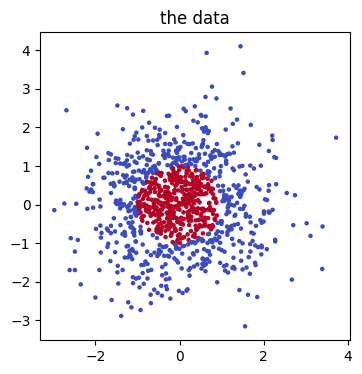

In [24]:
torch.manual_seed(0);
X = torch.randn(1000, 2)
y = (X.norm(dim=1) < 1.0).long()          # 1 inside the unit circle, 0 outside
plt.figure(figsize=(4, 4)); plt.scatter(X[:, 0], X[:, 1], c=y, s=5, cmap="coolwarm"); plt.title("the data"); plt.show()

### ✍️ Your turn: write a model and the training loop
- `TinyNet.__init__`: `self.layer1 = nn.Linear(2, 32)` and `self.layer2 = nn.Linear(32, 2)`
- `TinyNet.forward`: `layer1 → torch.relu → layer2` (returns logits of shape `(N, 2)`)
- the loop body: the 5 lines above

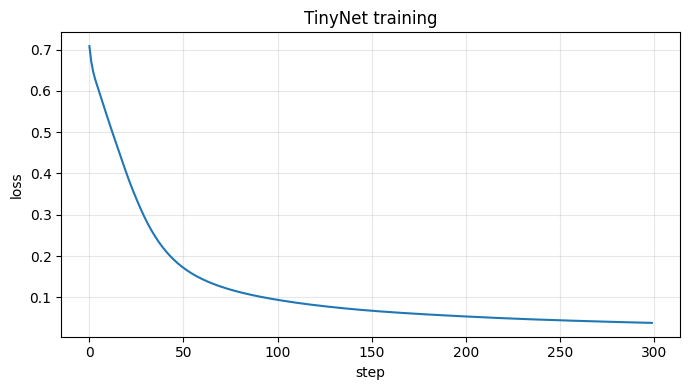

In [25]:
class TinyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(2, 32)
        self.layer2 = nn.Linear(32, 2)

    def forward(self, x):
        return self.layer2(torch.relu(self.layer1(x)))

torch.manual_seed(0);
model = TinyNet()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
losses = []
for step in range(300):
    logits = model(X)
    loss = F.cross_entropy(logits, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

viz.plot_curves({"train loss": losses}, title="TinyNet training")

In [26]:
accuracy = (model(X).argmax(dim=-1) == y).float().mean().item()
print(f"accuracy: {accuracy:.1%}")
check.equal("accuracy > 90%", accuracy > 0.9, True, hint="Check the order of the 5 lines.")

accuracy: 99.5%
✅ accuracy > 90% = True


## 9. Devices
Your Mac has an Apple GPU, which PyTorch calls **`"mps"`**. `model.to("mps")` and `tensor.to("mps")` move things there, and every tensor in one operation must be on the **same** device. In Part 5 we train on `mps`, which takes about 30 s.

In [27]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("will use:", device)

will use: mps


## ✅ Check your understanding
Answer out loud first, then open the answer.

<details><summary>1. What is the shape of <code>(B, T, d) @ (d, d_out)</code>? What does that mean for a Linear layer applied to a sequence?</summary>

`(B, T, d_out)`. The weight is shared and applied to **every token independently**. Linear layers (and the FFN in a Transformer) never mix information *between* tokens. Only attention does that.
</details>

<details><summary>2. Why do we call <code>optimizer.zero_grad()</code>?</summary>

`backward()` **adds** new gradients to `.grad`. Without zeroing, each step would use the sum of all past gradients.
</details>

<details><summary>3. Why subtract the max inside softmax?</summary>

Numerical stability: `exp` of large numbers overflows to `inf`. Softmax doesn't change when you subtract a constant, so subtracting the max keeps every exponent ≤ 0.
</details>

<details><summary>4. Why <code>.transpose(-2, -1)</code> rather than <code>.T</code> for batched tensors?</summary>

`.T` reverses **all** dims, so `(B, T, d)` becomes `(d, T, B)`. We only want to swap the last two.
</details>

<details><summary>5. What goes wrong with <code>x.view(B, h, T, d_k)</code> to split heads?</summary>

The shape is right but the numbers are scrambled: each "head" would mix values from different tokens. Use `view(B, T, h, d_k).transpose(1, 2)`.
</details>

**Next: `01_embeddings.ipynb`**